# 06 · Secondary experiment, comparative analysis and academic interpretation

**E1 (primary)** is a one-class VAE trained on 199,021 *normal* training transactions. **E2 (secondary)** is the identical architecture, hyperparameters, seeds and evaluation, trained on **all** 199,366 training transactions (345 frauds) with labels ignored everywhere: training, early stopping and threshold. Both are evaluated on the **same** held-out test set (42,647 normal, 73 fraud).

The figures and tables are produced by `python scripts/analyse_models.py`, which runs after `scripts/evaluate_detection.py`, so test labels are read only after predictions were saved. This notebook shows them and interprets them.

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/genAI")  # change this if the project folder lives elsewhere on Drive
else:
    PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROJECT_ROOT = PROJECT_ROOT.resolve()
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".cache" / "matplotlib"))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT.name)

Project root: genAI


In [2]:
import json
import subprocess
import pandas as pd
from IPython.display import Image

pd.set_option("display.width", 220)
METRICS = PROJECT_ROOT / "outputs" / "metrics"
if not (METRICS / "comparison_analysis.json").exists():
    subprocess.run([sys.executable, str(PROJECT_ROOT / "scripts" / "analyse_models.py")], check=True, cwd=PROJECT_ROOT)
analysis = json.loads((METRICS / "comparison_analysis.json").read_text())

## 1. Comparison table (test set, mean and std over 5 seeds)

In [3]:
pd.read_csv(METRICS / "comparison_table.csv", index_col=0).round(4)

,E1 normal-only (mean),E1 std,E2 unsupervised (mean),E2 std,difference E1 − E2,seeds where E1 higher
metric,,,,,,
PR-AUC (average precision),0.4316,0.0470,0.0377,0.0161,0.3938,5
ROC-AUC,0.9467,0.0155,0.8633,0.0162,0.0834,5
Precision,0.1036,0.0126,0.0423,0.0035,0.0613,5
Recall,0.6521,0.0716,0.2630,0.0245,0.3890,5
F1-score,0.1788,0.0211,0.0729,0.0059,0.1059,5
False-positive rate,0.0097,0.0007,0.0102,0.0006,-0.0005,1
Best epoch,167.8000,52.6517,154.2000,40.7394,13.6000,3
Training time (s),71.9289,22.8953,66.0668,17.2140,5.8622,3


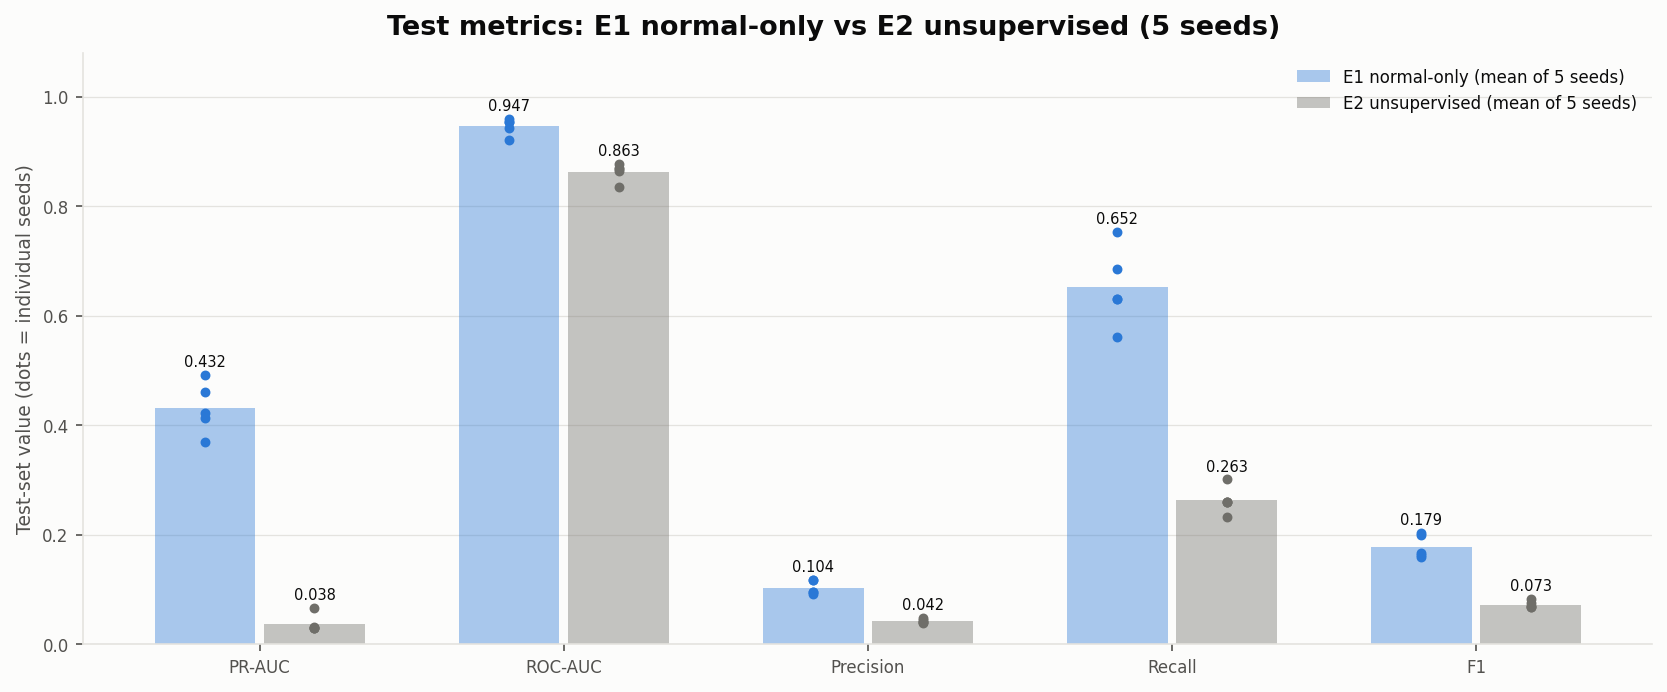

In [4]:
Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "analysis" / "metric_comparison.png"))

## 2. Training behaviour

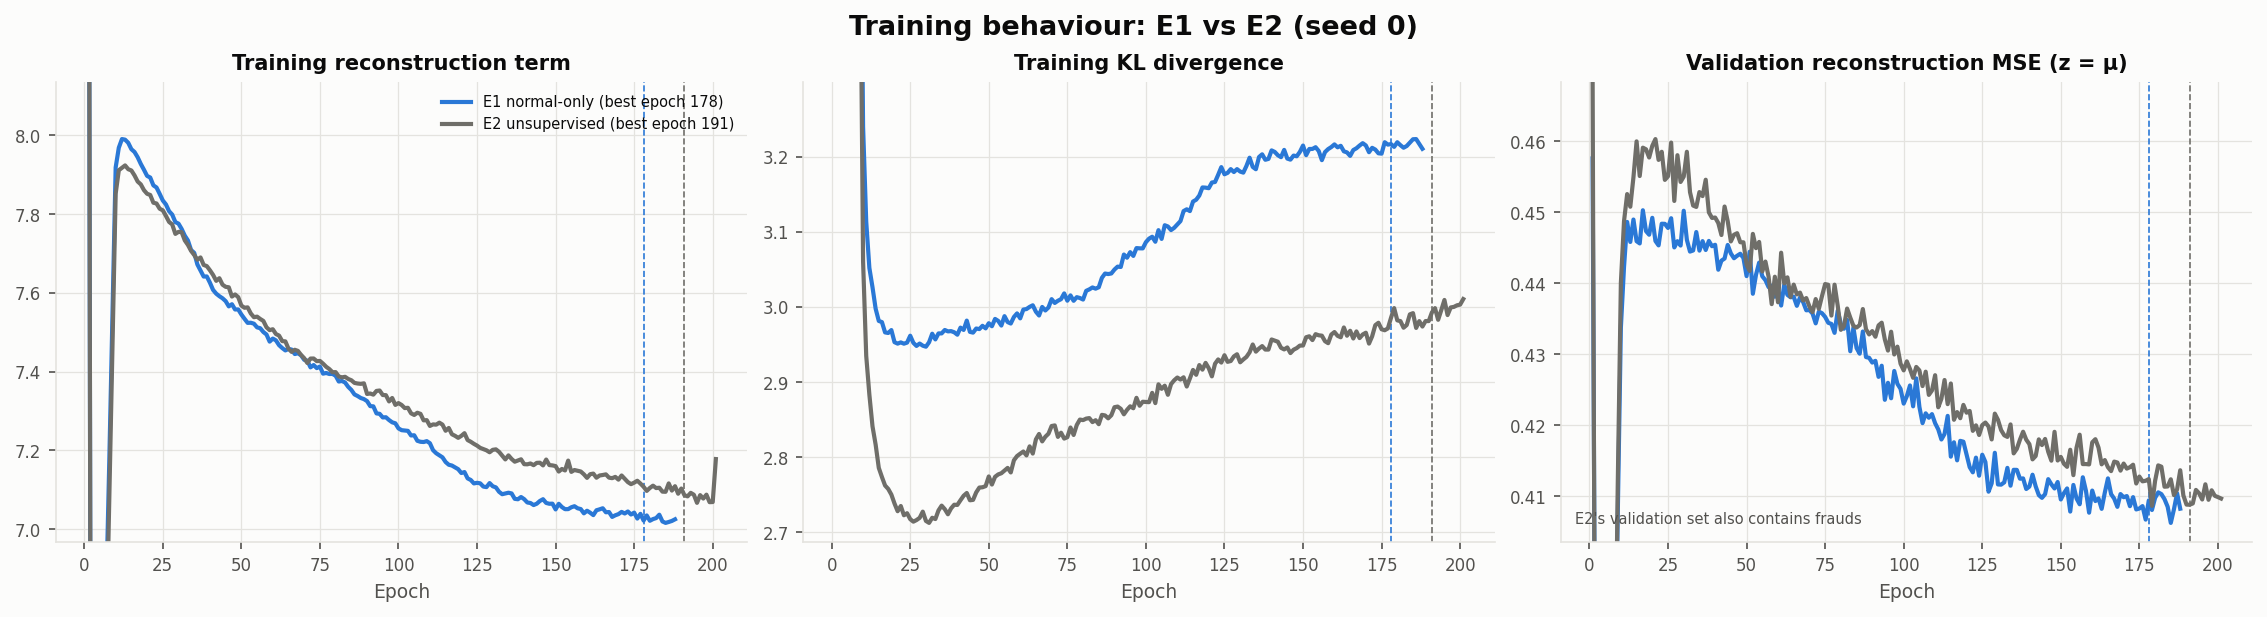

In [5]:
Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "analysis" / "training_comparison.png"))

Both models converge smoothly and early-stop at similar epochs (E1: 168 ± 53, E2: 154 ± 41). E2's reconstruction term on its training data stays slightly *higher* and its KL slightly *lower*: it spends capacity on the extreme fraud rows mixed into its training data. On validation data, E1 reaches a slightly lower reconstruction error (0.408 against 0.420). E2's validation set also contains frauds, so this comparison is indicative only.

## 3. Reconstruction-error distributions and fraud-detection behaviour

In [6]:
pd.read_csv(METRICS / "comparison_score_distributions.csv", index_col=0).round(3)

,normal_median,normal_p99,fraud_median,fraud_p25,fraud_p75,median_ratio_fraud_over_normal,share_of_frauds_above_normal_p99
model,,,,,,,
E1 normal-only,0.362,1.221,2.078,1.323,4.239,5.737,0.767
E2 unsupervised,0.351,1.253,0.862,0.544,1.288,2.455,0.260


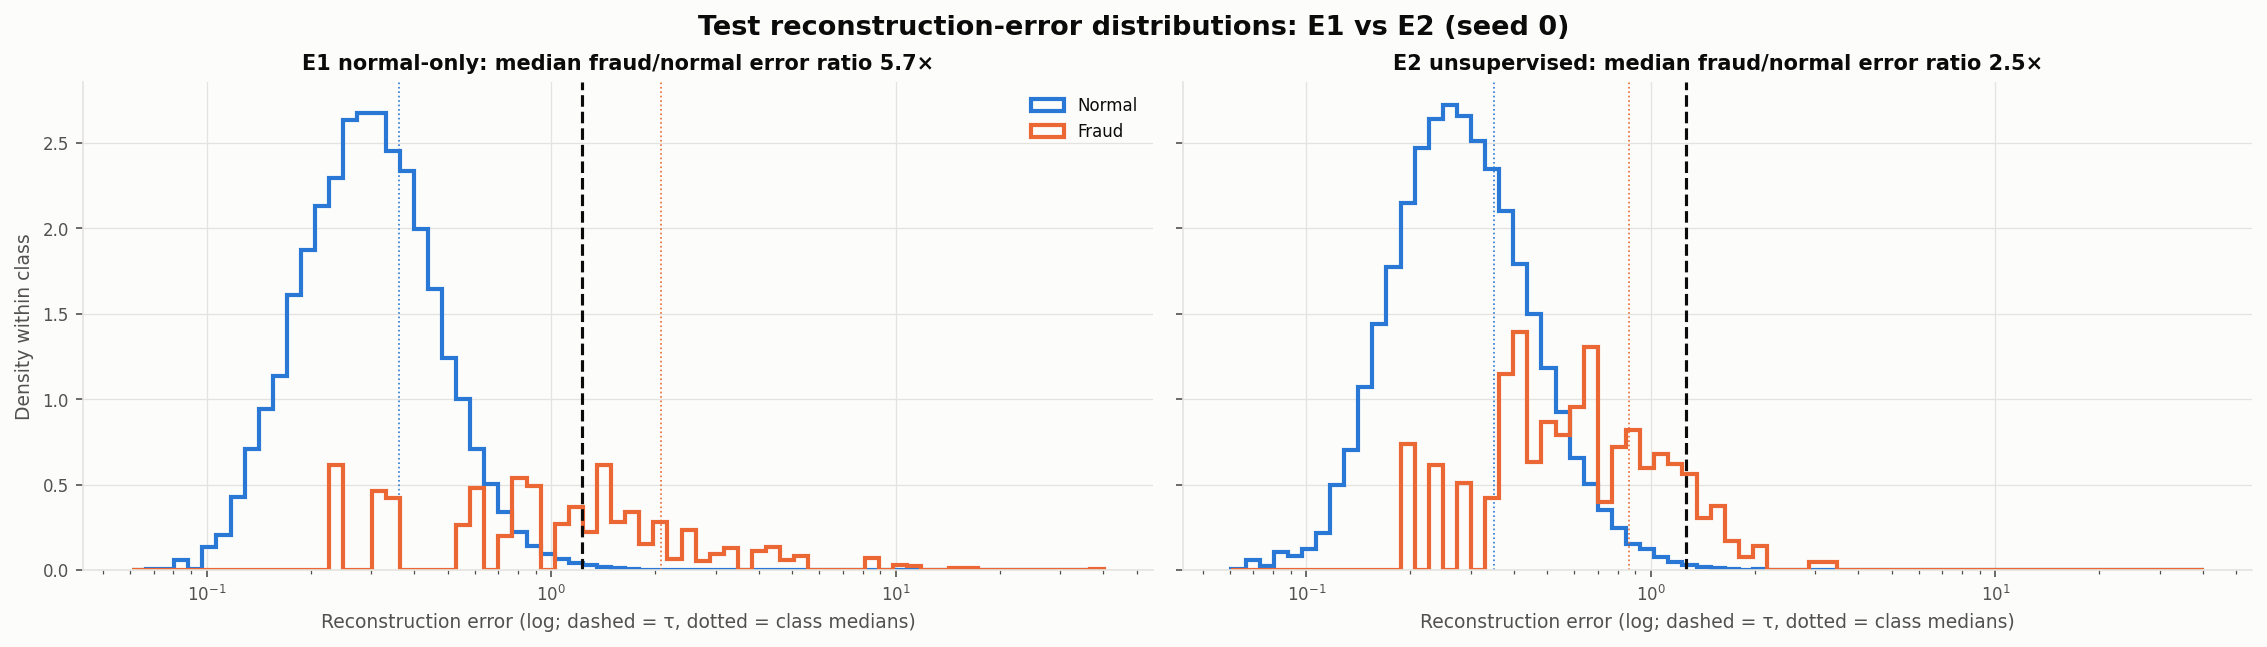

In [7]:
Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "analysis" / "score_distributions_e1_vs_e2.png"))

In [8]:
print("Frauds caught at the calibrated threshold (seed 0):", analysis["detection_overlap_seed0"])
pd.DataFrame({e: {k: v["frauds_caught"] for k, v in b.items()} for e, b in analysis["recall_at_budget"].items()}).rename_axis("top-k alerts")

Frauds caught at the calibrated threshold (seed 0): {'frauds': 73, 'caught_by_a': 55, 'caught_by_b': 19, 'caught_by_both': 18, 'only_a': 37, 'only_b': 1, 'missed_by_both': 17}


,e1,e2
top-k alerts,,
100,40,6
500,56,19
1000,60,28


**How contamination affects anomaly detection:**
- **E1 separates well:** for normal transactions both models reconstruct equally well (median error about 0.35). For frauds, E1's median error is **5.7× the normal median**, and 77% of frauds score above the normal 99th percentile.
- **E2 reconstructs fraud:** the ratio drops to **2.5×**, and only 26% of frauds exceed the normal 99th percentile. At about the same 1% false-positive rate, E2 catches 19 of 73 frauds against E1's 55, and 18 of E2's 19 are also caught by E1.
- **Why so few frauds matter so much:** the 345 training frauds are only 0.17% of E2's rows but carry about **4.1% of the total squared feature magnitude**, because their values are extreme. A squared-error objective therefore puts real effort into reconstructing them.
- **Why it carries over to unseen frauds:** frauds are strongly inter-correlated (EDA: |r| up to 0.97 among fraud rows), so learning a few training frauds teaches the decoder the general fraud pattern, and unseen test frauds become reconstructible too.
- **Conclusion:** a reconstruction-based detector is only as good as the cleanliness of its "normal" training data. Even a fraction of a percent of contamination can largely erase the signal.

## 4. Latent space (coloured by class only after training)

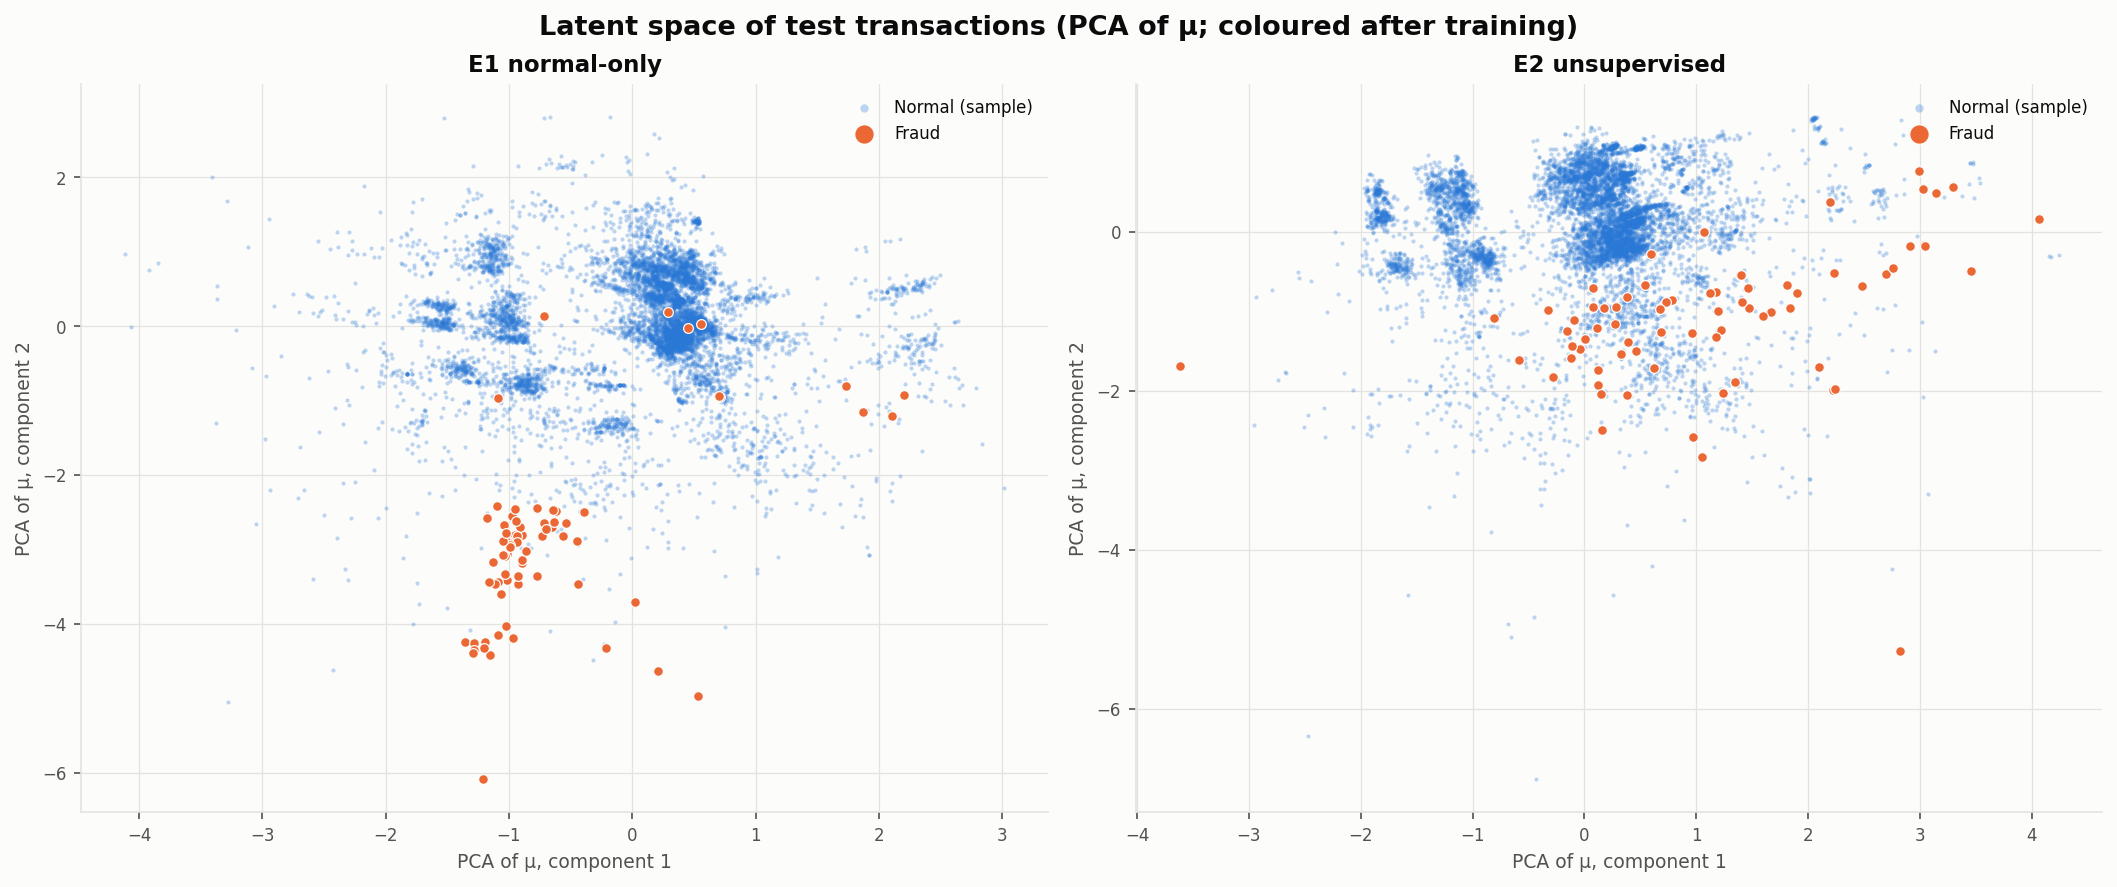

In [9]:
Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "analysis" / "latent_space_e1_vs_e2.png"))

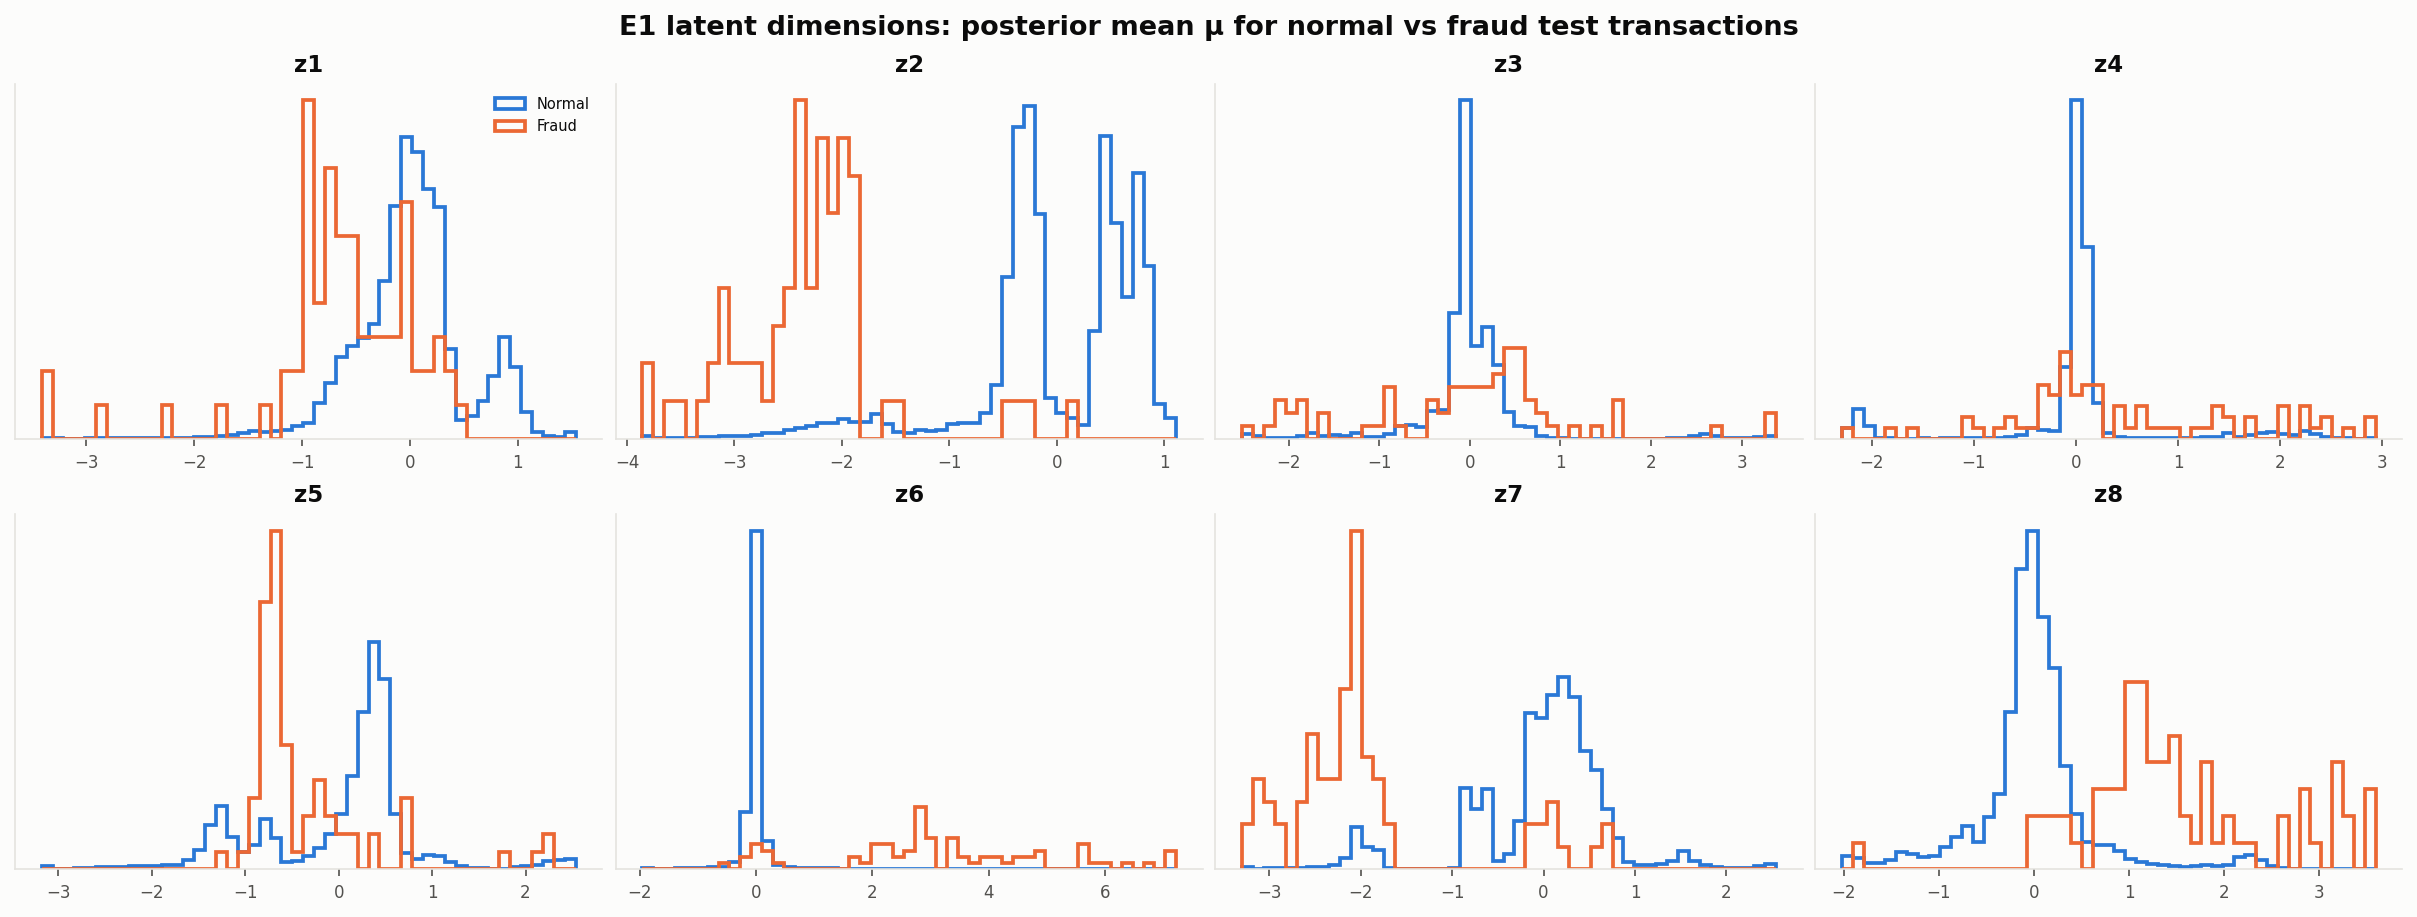

In [10]:
Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "analysis" / "latent_dims_e1.png"))

In [11]:
pd.DataFrame(analysis["latent"]).T.round(3)

,median_norm_normal,median_norm_fraud,centroid_distance,mean_within_normal_spread,pca_explained_variance,active_dims
e1,1.455851,4.931046,4.691766,1.653011,"[0.2034354954957962, 0.17836540937423706]",8
e2,1.360644,4.518894,3.858268,1.604348,"[0.21403637528419495, 0.1817820519208908]",8


- **E1:** without ever seeing a fraud, E1 maps most test frauds to a compact region away from normal transactions. Their median latent norm is 4.9, against 1.5 for normal transactions, and the class centroids are 4.7 apart (normal spread about 1.65). Several individual latent dimensions shift strongly for frauds.
- **E2:** frauds are still displaced in E2's latent space (centroid distance 3.9) but less sharply. Contamination therefore hurts the *reconstruction* score more than the latent representation, which is why E2's ELBO-based score (AP 0.117) beats its reconstruction score (0.038). Scores that use the latent space are a promising improvement.

## 5. Reconstruction behaviour

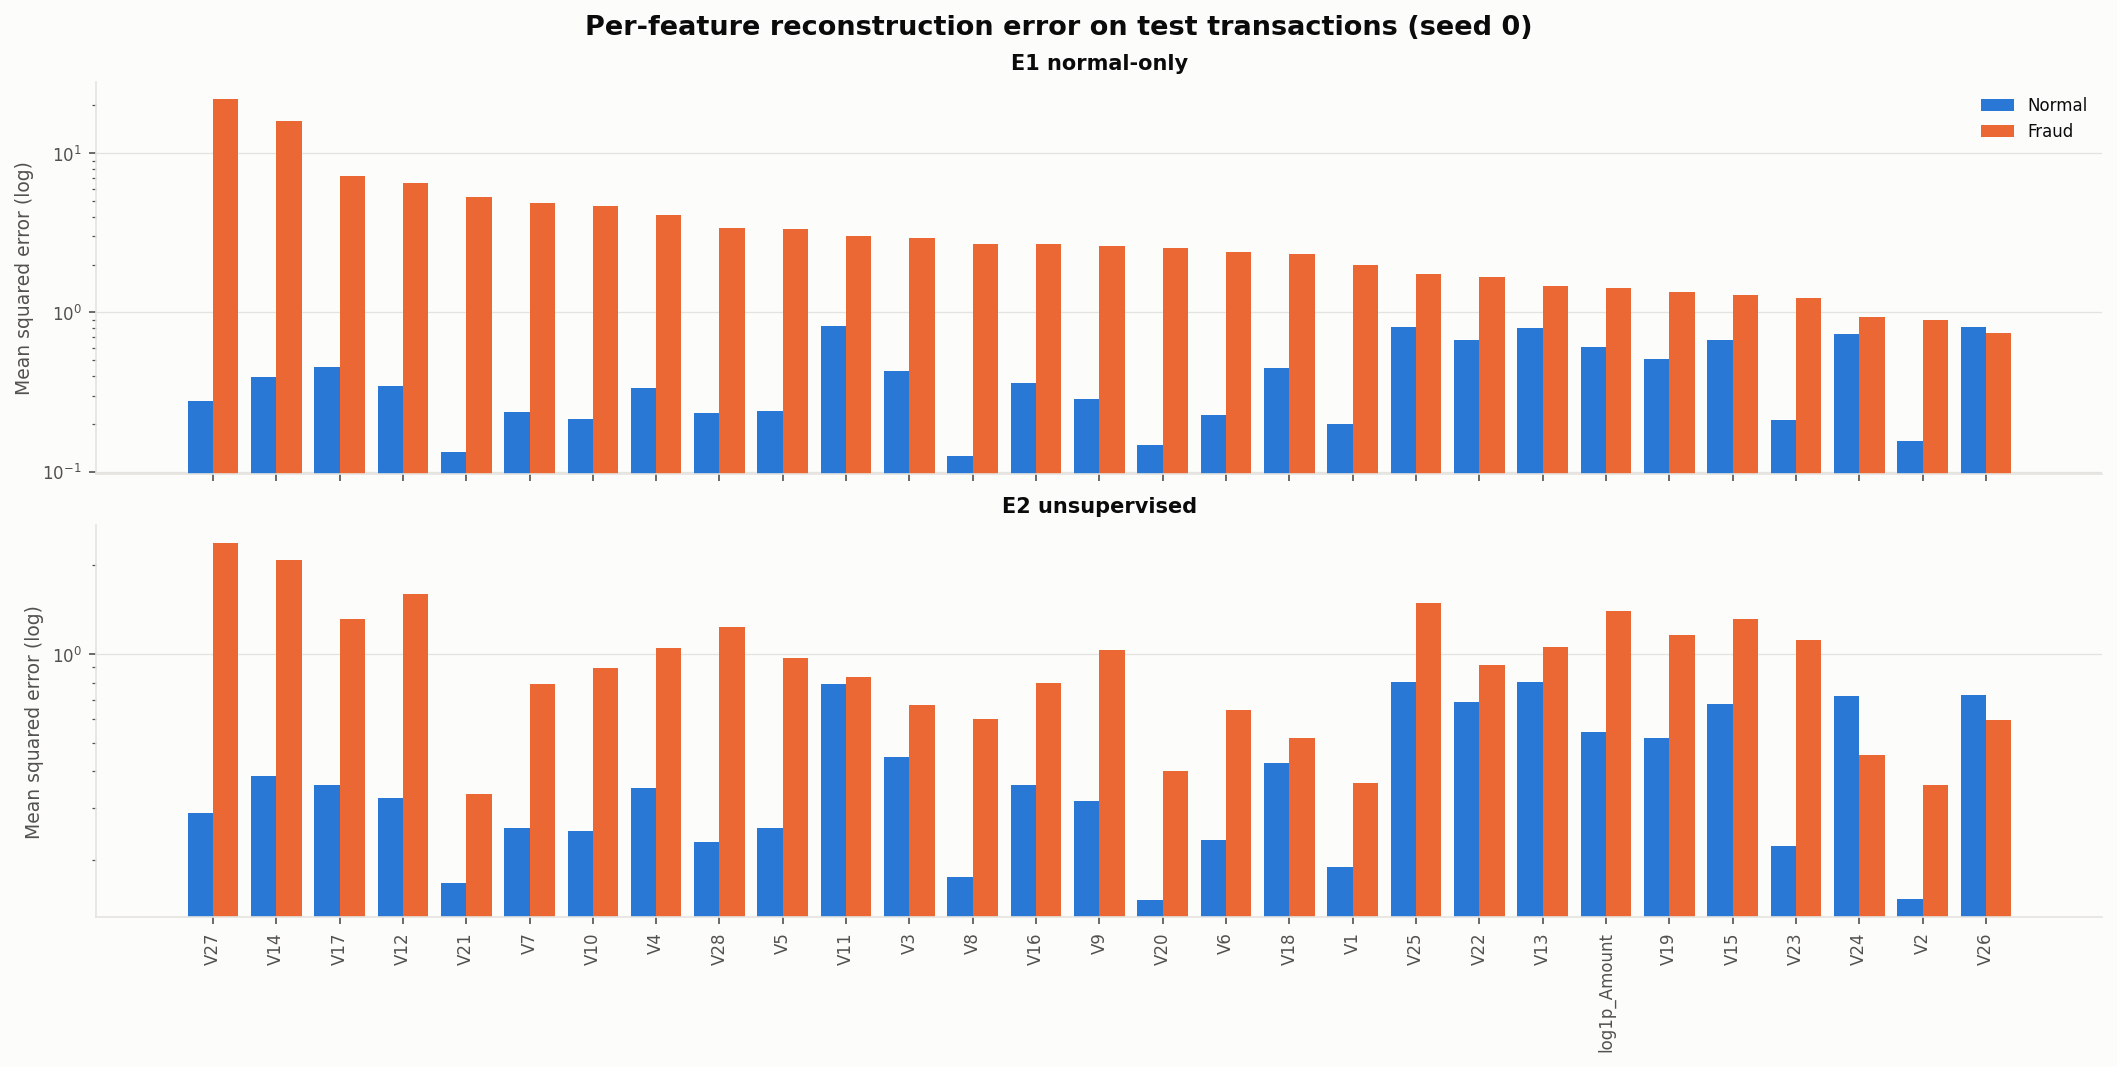

In [12]:
Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "analysis" / "per_feature_errors.png"))

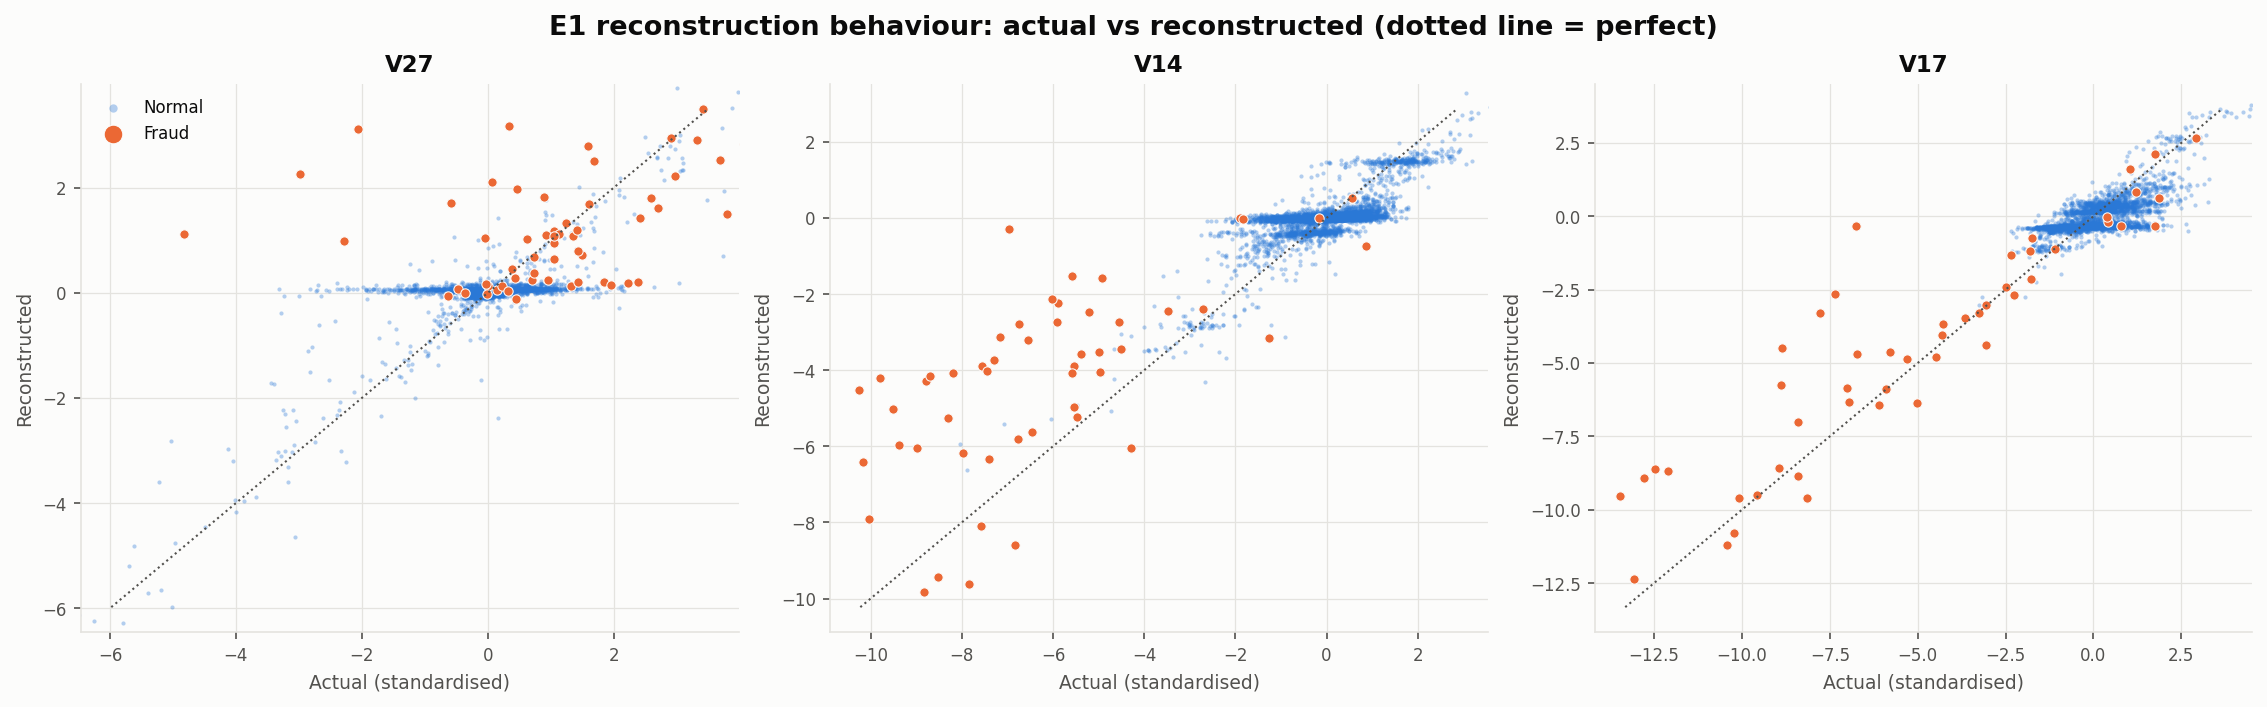

In [13]:
Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "analysis" / "reconstruction_scatter_e1.png"))

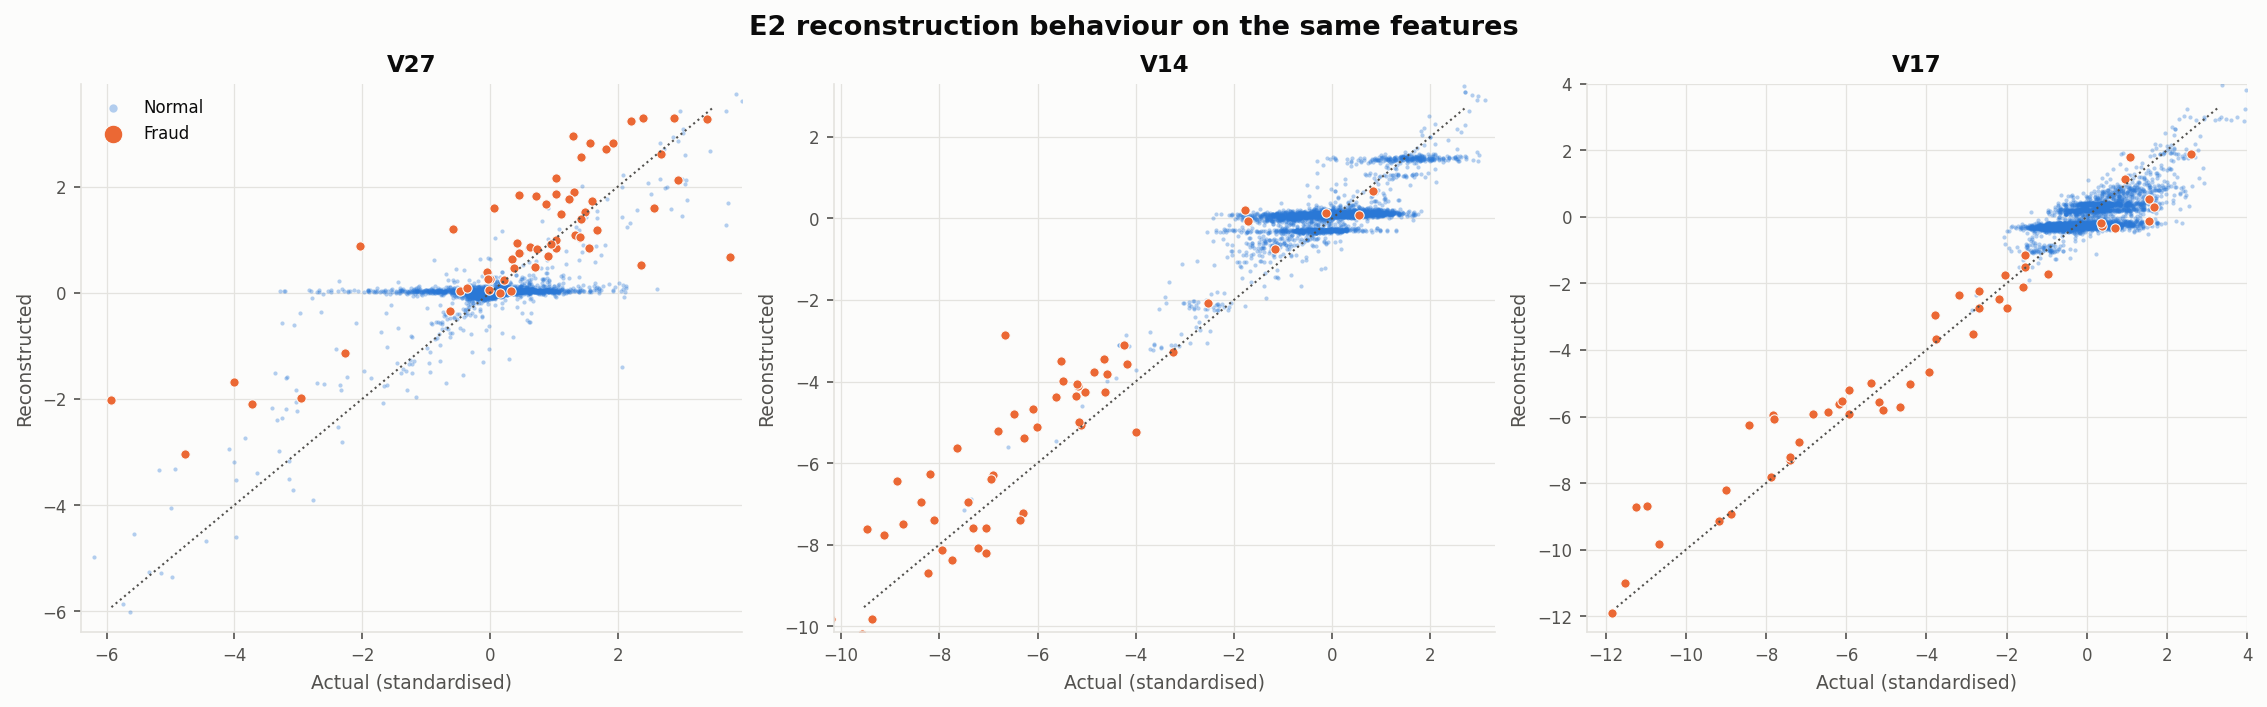

In [14]:
Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "analysis" / "reconstruction_scatter_e2.png"))

**Reconstruction error and anomaly detection:**
- **Where the error comes from:** the anomaly score is the average squared reconstruction error over 29 features, and for frauds it is concentrated in a few components. In E1, V27, V14, V17, V12 and V21 contribute about **50%** of the average fraud reconstruction error.
- **Why reconstruction fails for frauds:** the decoder pulls inputs towards the normal manifold. Frauds with extreme values (e.g. strongly negative V14) are reconstructed closer to normal values, which produces the large errors.
- **Missed frauds:** frauds that lie on or near the normal manifold reconstruct well and are missed. That is why reconstruction error **does not guarantee** detection of every fraud.
- **E2 behaves differently:** E2's reconstructions follow the extreme fraud values much more closely, which is the contamination effect seen directly.
- **Not a probability:** a high reconstruction error means "unusual relative to learned normal behaviour", not "probably fraud".

## 6. Effect of class imbalance

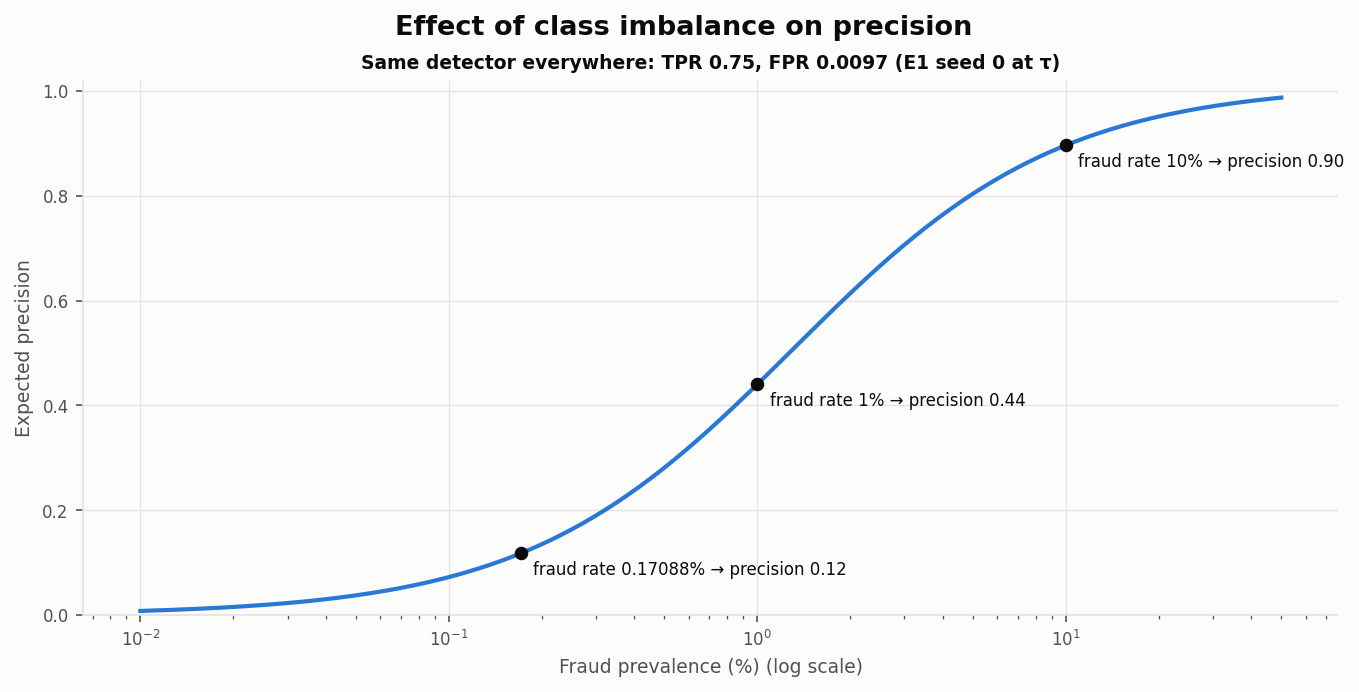

In [15]:
Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "analysis" / "precision_vs_prevalence.png"))

In [16]:
pd.Series(analysis["imbalance"]["expected_precision"]).rename("expected precision at this fraud rate").to_frame()

,expected precision at this fraud rate
0.0017088,0.117521
0.01,0.440044
0.05,0.803719
0.1,0.896313
0.5,0.987310


With fraud at 0.17%, a detector that catches 75% of frauds at a 0.97% false-positive rate (E1 seed 0) still yields only about **0.12 precision**, i.e. 7.5 false alarms per fraud caught. The same detector would reach about 0.44 precision at a 1% fraud rate and 0.90 at 10%. Low precision here comes mainly from the base rate, not from poor separation. For the same reason, PR-AUC (random baseline = 0.0017) is the primary metric and ROC-AUC (random = 0.5) looks optimistic.

## 7. Synthetic-data generation quality

In [17]:
g = json.loads((METRICS / "generation_summary.json").read_text())
pd.read_csv(METRICS / "generation_comparison.csv", index_col=0).round(3)

,mean_KS,mean_W1,std_ratio_V,tail_width_ratio,corr_frobenius,C2ST_logreg,C2ST_gboost,DCR_median
sampler,,,,,,,,
decoder_mean,0.221,0.375,0.490,0.546,3.803,0.590,1.000,1.891
decoder_mean_plus_noise,0.053,0.096,0.838,0.766,1.619,0.549,0.991,3.101
real vs real (reference),0.006,0.011,NaN,NaN,NaN,0.503,0.503,NaN


- **What works:** the decoder generates valid vectors (100% finite, non-negative Amount with 2 decimals) that are not copies of training data. They match the centre of the normal distribution and its main linear relationships.
- **Primary sampler is too smooth:** decoder-mean samples have about half the real spread and sit near an 8-dimensional surface.
- **Noise variant trade-off:** adding fitted decoder noise fixes most of the marginal mismatch (mean KS 0.05 against 0.22) but dilutes dependencies such as Amount–V2.
- **Detectability:** a non-linear classifier separates both samplers from real data, so the joint distribution is only partly captured.
- **Interpretability:** the samples exist only in the anonymised PCA feature space.

Details are in notebook 04.

## 8. Limitations

**Dataset:**
- **Age and span:** the transactions come from **September 2013** and cover only **two days**. Results **cannot automatically be generalised to contemporary banking systems**, where payment channels, fraud tactics and customer behaviour differ.
- **Anonymised features:** `V1–V28` are **anonymised PCA components**, so their meaning is unknown, they cannot be checked semantically, and the providers fitted the PCA on all rows.
- **Few frauds:** only 73 test frauds, so confidence intervals are wide (E1 seed-0 AP 95% CI 0.38–0.62) and differences between seeds are within noise.
- **No context:** there are no customer, merchant or time-sequence features.

**Method and architecture:**
- **Not every fraud is detected:** reconstruction error does **not** guarantee that every fraudulent transaction will be detected; frauds that resemble normal transactions are missed.
- **Scores are not probabilities:** none of the scores is a calibrated fraud probability.
- **Protocol:** the primary set-up is **one-class / semi-supervised**, because labels select the normal training rows. It is **not** strictly fully unsupervised, and the fully unsupervised variant performs much worse.
- **Precision:** extreme class imbalance limits precision at any realistic false-positive rate.
- **Generator:** a unit-variance Gaussian decoder with a small latent space gives smooth, thin-tailed samples and misses non-linear joint structure.
- **Synthetic samples:** they live in anonymised feature space, carry no labels, and are not verified transactions.
- **Fixed hyperparameters:** they were fixed in advance and not tuned. Sensitivity to latent size, β and scaling has not been explored yet.

## 9. Future work

- **Better scores:** combine reconstruction with latent and KL information (ELBO, latent density), which held up better under contamination.
- **Robust training:** trimmed or robust losses, or iterative removal of high-error rows, so unlabelled data can be used safely.
- **Better generators:** learned per-feature variance, heavy-tailed likelihoods, normalising-flow priors and β-VAE variants for sharper, more faithful samples; conditional VAEs for controlled generation.
- **Sensitivity analyses:** latent dimension, β, a deterministic-autoencoder baseline, RobustScaler, an hour-of-day feature, time-ordered splits and deduplicated data.
- **Newer data:** validation on recent, interpretable and longer-horizon transaction data, and studies of concept drift.